# $\arctan(1/\sqrt{11})/\sqrt{11}$: historical CMF bounds

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from ramanujantools import Matrix
from ramanujantools.cmf.pfq import pFq

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}
x0, x1, y0 = sp.symbols('x0 x1 y0')
target = lambda: (1/arb(11).sqrt()).atan()/arb(11).sqrt()


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Alladi–Robinson (1980): $\arctan(1/\sqrt{11})/\sqrt{11}$

[Quadratic integral and measure formula](https://www.math.ru.nl/~wzudilin/gat/oALLADI4.txt).

**CMF:** ${}_2F_1(-1/11)$, rank 2. **Start:** $(1/2,1;3/2)$.
**Direction:** $(1,1;2)$. Even source indices N use N/2 steps.
**Readout:** $-W_{10}/[12(2W_{00}-W_{10})]$.

In [5]:
cmf = pFq(2, 1, -sp.Rational(1, 11))
start = {x0: sp.Rational(1, 2), x1: 1, y0: sp.Rational(3, 2)}
trajectory = {x0: 1, x1: 1, y0: 2}
walks = cmf.walk(trajectory, [N // 2 for N in DEPTHS], start)
approximants = [-1 * M[1, 0] / (12 * (2 * M[0, 0] - M[1, 0])) for M in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Alladi–Robinson family'] = (DEPTHS, deltas)
accuracy['Alladi–Robinson family'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.326999645318


## 2. Hata (1992): specialization of Theorem 3.1

[Theorem 3.1 and Eq. (2.6), pp. 341-346](https://matwbn.icm.edu.pl/ksiazki/aa/aa60/aa6043.pdf).

**CMF:** ${}_2F_1(-1/11)$, rank 2. **Start:** $(1,1/2;3/2)$.
**Direction:** $(4,4;9)$. Source index N uses N/4 steps.
**Readout:** $-(CW)_0/[11(BW)_0]$, with $C=(0,11/12)$ and $B=(2,-1)$.

Only multiples of 4 are sampled; source index 500 is 125 CMF steps.

In [7]:
cmf = pFq(2, 1, -sp.Rational(1, 11))
start = {x0: 1, x1: sp.Rational(1, 2), y0: sp.Rational(3, 2)}
trajectory = {x0: 4, x1: 4, y0: 9}
depths = [N for N in DEPTHS if N % 4 == 0]
walks = cmf.walk(trajectory, [N // 4 for N in depths], start)
C = Matrix([[0, sp.Rational(11, 12)]])
B = Matrix([[2, -1]])
approximants = [-(C * M)[0] / (11 * (B * M)[0]) for M in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Hata (1992), theorem specialization'] = (depths, deltas)
accuracy['Hata (1992), theorem specialization'] = [value[1] for value in measurements]
print(f"delta at N = {depths[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.378815715232


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

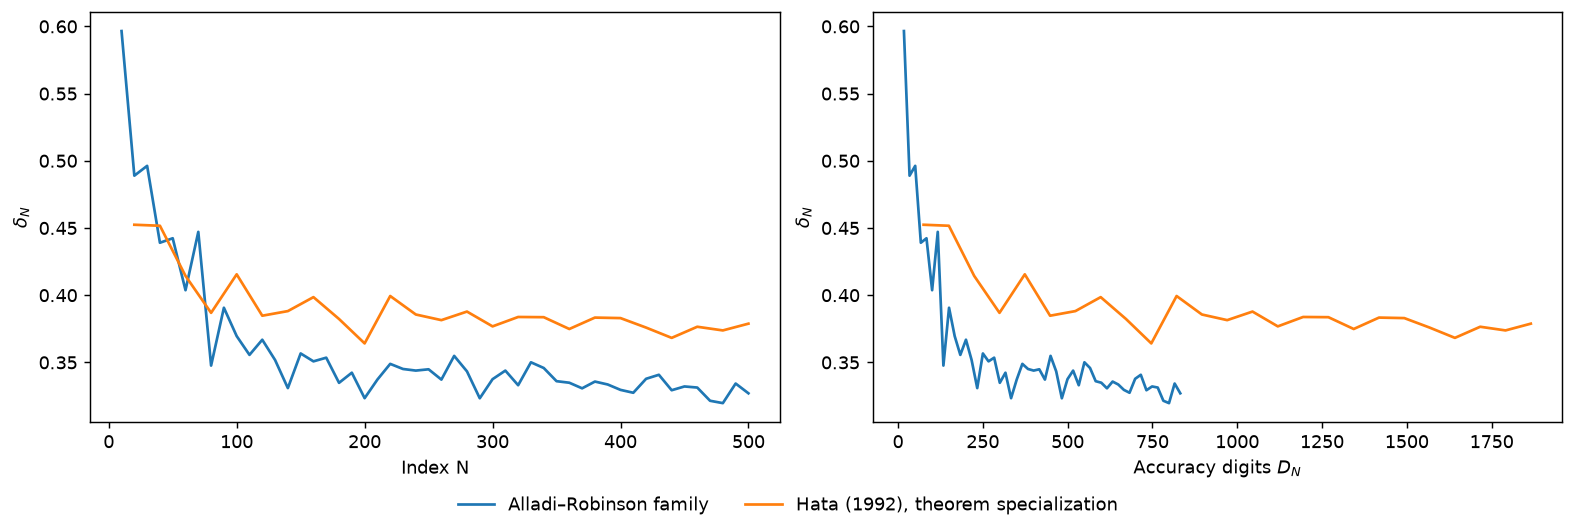

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [11]:
bounds = {
    'Alladi–Robinson family': '4.187982159589',
    'Hata (1992), theorem specialization': '3.709757900017...',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| Alladi–Robinson family | 4.187982159589 | 0.326999645318 (N = 500) |
| Hata (1992), theorem specialization | 3.709757900017... | 0.378815715232 (N = 500) |